# Reto Relámpago: Derroten a las Clásicas

## Notebook base — protocolo fijo de entrenamiento

Este notebook trae el protocolo que **todos los equipos usan igual**, para que la comparación sea justa:

1. Carga de CIFAR-10, redimensionada a 224×224 (igual para todos)
2. Una función `entrenar_con_presupuesto` que limita el entrenamiento a **15 épocas o 30 minutos**, lo que se cumpla primero
3. Los 3 baselines (AlexNet, VGG16, ResNet18) usados como **extractores de características preentrenados en ImageNet** — backbone congelado, solo se entrena una cabeza nueva
4. Una sección marcada **"SU ARQUITECTURA AQUÍ"** — ahí van a poner su CNN propia, entrenada **completamente desde cero** (menos de 1,000,000 de parámetros)
5. Una tabla comparativa final, generada automáticamente, con parámetros totales Y entrenables

> **No modifiquen las celdas de la Sección 1 y 2** (carga de datos y función de presupuesto) — son el protocolo común. Solo agreguen su código en la Sección 4.

> **Recomendación:** corran este notebook en Google Colab con GPU (`Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU`). Sin GPU, los 30 minutos de presupuesto rendirán muchas menos épocas — y a 224×224 cada época es más pesada que a una resolución menor.

## Setup

In [6]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torchvision.models import (
    alexnet, AlexNet_Weights,
    vgg16, VGG16_Weights,
    resnet18, ResNet18_Weights,
)
from torch.utils.data import DataLoader, random_split
from datasets import load_dataset  # CIFAR-10 se descarga de Hugging Face
import matplotlib.pyplot as plt
import numpy as np
import time

torch.manual_seed(42)

# GPU para los 4 modelos: NVIDIA (cuda, ej. Colab) o Apple Silicon (mps); si no hay ninguna, CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Usando: {device}")
if device.type == "cpu":
    print("Sin GPU: considera usar Google Colab con GPU para aprovechar mejor el presupuesto de 30 min.")
else:
    _ = (torch.ones(2, 2, device=device) @ torch.ones(2, 2, device=device)).sum().item()  # prueba rápida de la GPU
    print("GPU lista.")

Usando: mps
GPU lista.


---
# 1. Datos: CIFAR-10 a 224×224, normalizado como ImageNet (NO modificar)

Redimensionamos a 224×224 porque los 3 baselines se usan como extractores de características **preentrenados en ImageNet**, y esperan ese tamaño de entrada (y esa normalización) para que las características que extraen sean las que aprendieron originalmente. CIFAR-10 nace en 32×32, así que las imágenes se verán borrosas al escalarlas — es normal y es el mismo trade-off que enfrenta cualquiera que reutilice un modelo preentrenado con datos de otra fuente.

In [7]:
TAMANO = 224
BATCH_SIZE = 64

# Mismas estadísticas de normalización con las que se preentrenaron los baselines en ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transform = T.Compose([
    T.Resize((TAMANO, TAMANO)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


def cifar10_desde_hf(split, transform):
    """Descarga CIFAR-10 de Hugging Face (uoft-cs/cifar10) y lo guarda en un objeto
    CIFAR10 de torchvision, para que se use igual que antes (.classes, num_workers, etc.)."""
    hf = load_dataset("uoft-cs/cifar10", split=split, cache_dir="./data/hf")
    ds = torchvision.datasets.CIFAR10.__new__(torchvision.datasets.CIFAR10)
    torchvision.datasets.VisionDataset.__init__(ds, root="./data", transform=transform)
    ds.train = split == "train"
    ds.data = np.stack([np.asarray(img.convert("RGB")) for img in hf["img"]])  # (N, 32, 32, 3) uint8
    ds.targets = list(hf["label"])
    ds.classes = hf.features["label"].names
    ds.class_to_idx = {c: i for i, c in enumerate(ds.classes)}
    return ds


train_full = cifar10_desde_hf("train", transform)
test_set = cifar10_desde_hf("test", transform)

# Separamos un 10% del set de entrenamiento como validación
n_val = int(0.1 * len(train_full))
n_train = len(train_full) - n_val
train_set, val_set = random_split(train_full, [n_train, n_val], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Entrenamiento: {len(train_set):,} imágenes")
print(f"Validación:    {len(val_set):,} imágenes")
print(f"Prueba:        {len(test_set):,} imágenes")
print(f"Clases: {train_full.classes}")

Entrenamiento: 45,000 imágenes
Validación:    5,000 imágenes
Prueba:        10,000 imágenes
Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


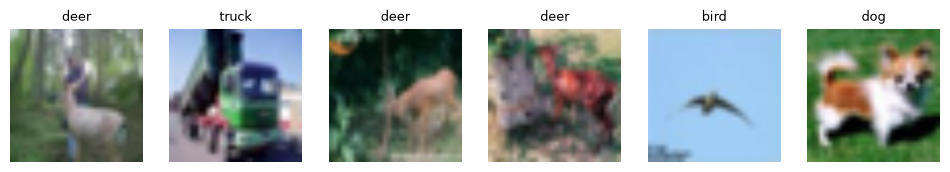

In [8]:
# Un vistazo rápido a los datos
imgs, etiquetas = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
std = torch.tensor(IMAGENET_STD).view(3,1,1)
for i, ax in enumerate(axes):
    img = imgs[i] * std + mean
    ax.imshow(img.permute(1,2,0).clamp(0,1))
    ax.set_title(train_full.classes[etiquetas[i]], fontsize=9)
    ax.axis("off")
plt.show()

---
# 2. El protocolo de presupuesto (NO modificar)

Esta función entrena cualquier modelo con el **mismo límite para todos**: 15 épocas o 30 minutos de reloj, lo que ocurra primero. El optimizador solo actualiza los parámetros con `requires_grad=True` — en los baselines eso es solo la cabeza nueva; en `MiCNN`, toda la red.

In [9]:
def contar_parametros_entrenables(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def contar_parametros_totales(modelo):
    return sum(p.numel() for p in modelo.parameters())


def entrenar_con_presupuesto(modelo, nombre, train_loader, val_loader,
                              max_epocas=15, max_segundos=1800, lr=0.001):
    """Entrena `modelo` bajo el presupuesto fijo del reto. Solo actualiza
    los parámetros con requires_grad=True (en feature extraction, la cabeza
    nueva; en MiCNN, toda la red). Regresa un dict con el historial, el
    tiempo usado, y si se detuvo por tope de tiempo."""
    modelo = modelo.to(device)
    parametros_a_entrenar = [p for p in modelo.parameters() if p.requires_grad]
    optimizer = optim.Adam(parametros_a_entrenar, lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    historial = {"train_loss": [], "val_acc": []}

    inicio = time.time()
    detenido_por_tiempo = False
    epocas_completadas = 0

    for epoca in range(max_epocas):
        if time.time() - inicio > max_segundos:
            detenido_por_tiempo = True
            break

        modelo.train()
        total_loss = 0.0
        n_batches = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(modelo(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
            if time.time() - inicio > max_segundos:
                detenido_por_tiempo = True
                break
        historial["train_loss"].append(total_loss / max(n_batches, 1))

        modelo.eval()
        correctos, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = modelo(x).argmax(dim=1)
                correctos += (pred == y).sum().item()
                total += y.size(0)
        acc = correctos / total
        historial["val_acc"].append(acc)
        epocas_completadas += 1

        tiempo_transcurrido = time.time() - inicio
        print(f"[{nombre}] Época {epocas_completadas}/{max_epocas} — "
              f"loss: {historial['train_loss'][-1]:.3f} — val_acc: {acc:.3f} — "
              f"{tiempo_transcurrido:.0f}s")

        if detenido_por_tiempo:
            break

    tiempo_total = time.time() - inicio
    return {
        "nombre": nombre,
        "modelo": modelo,
        "historial": historial,
        "epocas_completadas": epocas_completadas,
        "tiempo_segundos": tiempo_total,
        "detenido_por_tiempo": detenido_por_tiempo,
        "parametros_entrenables": contar_parametros_entrenables(modelo),
        "parametros_totales": contar_parametros_totales(modelo),
    }


def evaluar_en_test(modelo, test_loader):
    modelo.eval()
    correctos, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            pred = modelo(x).argmax(dim=1)
            correctos += (pred == y).sum().item()
            total += y.size(0)
    return correctos / total


MAX_EPOCAS = 15
MAX_SEGUNDOS = 30 * 60  # 30 minutos, el presupuesto del reto
print(f"Presupuesto fijo: {MAX_EPOCAS} épocas o {MAX_SEGUNDOS/60:.0f} minutos, lo que ocurra primero.")

Presupuesto fijo: 15 épocas o 30 minutos, lo que ocurra primero.


---
# 3. Los baselines: AlexNet, VGG16 y ResNet18 — feature extraction con pesos de ImageNet

Para cada uno: (1) se cargan los pesos preentrenados en ImageNet, (2) se **congela todo el backbone** (`requires_grad = False` en todos los parámetros), y (3) se **reemplaza la capa clasificadora final** por una nueva para las 10 clases de CIFAR-10 — esa capa nueva nace con `requires_grad=True` y es la única que se entrena. Esta celda puede tardar bastante — es normal, sobre todo VGG16.

In [10]:
resultados = {}

modelo_alexnet = alexnet(weights=AlexNet_Weights.DEFAULT)
for p in modelo_alexnet.parameters():
    p.requires_grad = False
in_feats = modelo_alexnet.classifier[6].in_features
modelo_alexnet.classifier[6] = nn.Linear(in_feats, 10)  # nueva cabeza: la única parte entrenable

resultados["AlexNet"] = entrenar_con_presupuesto(
    modelo_alexnet, "AlexNet", train_loader, val_loader,
    max_epocas=MAX_EPOCAS, max_segundos=MAX_SEGUNDOS
)

[AlexNet] Época 1/15 — loss: 0.732 — val_acc: 0.798 — 50s
[AlexNet] Época 2/15 — loss: 0.629 — val_acc: 0.808 — 99s
[AlexNet] Época 3/15 — loss: 0.604 — val_acc: 0.813 — 149s
[AlexNet] Época 4/15 — loss: 0.594 — val_acc: 0.820 — 199s
[AlexNet] Época 5/15 — loss: 0.587 — val_acc: 0.821 — 249s
[AlexNet] Época 6/15 — loss: 0.585 — val_acc: 0.813 — 299s
[AlexNet] Época 7/15 — loss: 0.577 — val_acc: 0.826 — 349s
[AlexNet] Época 8/15 — loss: 0.581 — val_acc: 0.818 — 565s
[AlexNet] Época 9/15 — loss: 0.573 — val_acc: 0.825 — 616s
[AlexNet] Época 10/15 — loss: 0.573 — val_acc: 0.816 — 667s
[AlexNet] Época 11/15 — loss: 0.572 — val_acc: 0.827 — 717s
[AlexNet] Época 12/15 — loss: 0.567 — val_acc: 0.820 — 768s
[AlexNet] Época 13/15 — loss: 0.568 — val_acc: 0.822 — 820s
[AlexNet] Época 14/15 — loss: 0.561 — val_acc: 0.813 — 870s
[AlexNet] Época 15/15 — loss: 0.570 — val_acc: 0.828 — 921s


In [11]:
modelo_vgg16 = vgg16(weights=VGG16_Weights.DEFAULT)
for p in modelo_vgg16.parameters():
    p.requires_grad = False
in_feats = modelo_vgg16.classifier[6].in_features
modelo_vgg16.classifier[6] = nn.Linear(in_feats, 10)  # nueva cabeza: la única parte entrenable

resultados["VGG16"] = entrenar_con_presupuesto(
    modelo_vgg16, "VGG16", train_loader, val_loader,
    max_epocas=MAX_EPOCAS, max_segundos=MAX_SEGUNDOS
)

KeyboardInterrupt: 

In [12]:
modelo_resnet18 = resnet18(weights=ResNet18_Weights.DEFAULT)
for p in modelo_resnet18.parameters():
    p.requires_grad = False
in_feats = modelo_resnet18.fc.in_features
modelo_resnet18.fc = nn.Linear(in_feats, 10)  # nueva cabeza: la única parte entrenable

resultados["ResNet18"] = entrenar_con_presupuesto(
    modelo_resnet18, "ResNet18", train_loader, val_loader,
    max_epocas=MAX_EPOCAS, max_segundos=MAX_SEGUNDOS
)

[ResNet18] Época 1/15 — loss: 0.850 — val_acc: 0.791 — 104s
[ResNet18] Época 2/15 — loss: 0.622 — val_acc: 0.785 — 204s
[ResNet18] Época 3/15 — loss: 0.592 — val_acc: 0.797 — 304s
[ResNet18] Época 4/15 — loss: 0.576 — val_acc: 0.802 — 405s
[ResNet18] Época 5/15 — loss: 0.566 — val_acc: 0.802 — 505s
[ResNet18] Época 6/15 — loss: 0.563 — val_acc: 0.802 — 606s
[ResNet18] Época 7/15 — loss: 0.558 — val_acc: 0.805 — 706s
[ResNet18] Época 8/15 — loss: 0.555 — val_acc: 0.804 — 807s
[ResNet18] Época 9/15 — loss: 0.545 — val_acc: 0.808 — 907s
[ResNet18] Época 10/15 — loss: 0.547 — val_acc: 0.810 — 1007s
[ResNet18] Época 11/15 — loss: 0.546 — val_acc: 0.807 — 1108s
[ResNet18] Época 12/15 — loss: 0.540 — val_acc: 0.806 — 1209s
[ResNet18] Época 13/15 — loss: 0.538 — val_acc: 0.812 — 1310s
[ResNet18] Época 14/15 — loss: 0.536 — val_acc: 0.807 — 1410s
[ResNet18] Época 15/15 — loss: 0.535 — val_acc: 0.806 — 1511s


---
# 4. SU ARQUITECTURA AQUÍ

Diseñen su CNN en la clase `MiCNN` de abajo y entrénenla **completamente desde cero** (sin pesos preentrenados — toda la red nace con pesos aleatorios y `requires_grad=True`). **Requisito: menos de 1,000,000 de parámetros entrenables** — como aquí se entrena toda la red, eso equivale al total de parámetros de su arquitectura. La celda siguiente revisa esto automáticamente y lanza un error si se pasan.

Recuerden contra qué compiten: los 3 baselines no aprenden a ver desde cero, parten del conocimiento visual de ImageNet y solo ajustan una cabeza pequeña. Su CNN no tiene ese atajo.

Ideas que pueden explorar (todas permitidas por las reglas del reto):
- Menos canales por capa que las arquitecturas clásicas (no necesitan 64→128→256→512)
- `BatchNorm2d` después de cada convolución, para entrenar más rápido y estable
- `Dropout` antes de la capa final, para regularizar
- Pooling global (`nn.AdaptiveAvgPool2d(1)`) en vez de un `Flatten` gigante antes del clasificador — reduce muchísimo los parámetros de la capa densa final
- Data augmentation en las transformaciones de `train_loader` (si lo hacen, créenlo en una celda nueva — no modifiquen `train_loader` de la Sección 1 directamente, dupliquen el dataset con sus propias transforms)

In [13]:
def bloque_conv(c_in, c_out):
    """Conv 3x3 -> BN -> ReLU -> Conv 3x3 -> BN -> ReLU -> MaxPool 2x2"""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),  # sin bias: BatchNorm ya tiene su propio desplazamiento (beta)
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),                         # alto y ancho a la mitad
    )


class MiCNN(nn.Module):
    """AvgPool de entrada (224 -> 32), 4 bloques de doble conv 3x3 + BatchNorm
    (canales 32-64-128-192), Global Average Pooling, Dropout y una capa densa.
    843,114 parámetros."""

    def __init__(self, num_classes=10, p_dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            # Las imágenes son CIFAR de 32x32 agrandadas a 224: regresarlas a 32 no pierde
            # información y cada época cuesta ~49x menos cómputo (0 parámetros).
            # Es lo mismo que hacen AlexNet (stride 4) y ResNet (stride 2 + pool) en su primera capa.
            nn.AvgPool2d(kernel_size=7),  # 3x224x224 -> 3x32x32
            bloque_conv(3, 32),           # 3x32x32   -> 32x16x16
            bloque_conv(32, 64),          # 32x16x16  -> 64x8x8
            bloque_conv(64, 128),         # 64x8x8    -> 128x4x4
            bloque_conv(128, 192),        # 128x4x4   -> 192x2x2
            nn.AdaptiveAvgPool2d(1),      # 192x2x2   -> 192x1x1 (un número por canal)
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),              # -> 192
            nn.Dropout(p_dropout),     # apaga el 40% solo en entrenamiento
            nn.Linear(192, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.clasificador(x)
        return x  # logits (CrossEntropyLoss ya aplica softmax)


mi_modelo = MiCNN()
mis_parametros = contar_parametros_entrenables(mi_modelo)
print(f"Parámetros entrenables de su CNN: {mis_parametros:,}")

assert mis_parametros < 1_000_000, (
    f"Su modelo tiene {mis_parametros:,} parámetros entrenables — el límite del reto es 1,000,000. "
    "Reduzcan canales, usen pooling global, o quiten alguna capa."
)
assert mis_parametros > 0, "Definan su arquitectura antes de continuar."
print("Dentro del límite de parámetros del reto.")

# Verificación rápida de formas con la entrada del protocolo (224x224)
with torch.no_grad():
    salida = mi_modelo.eval()(torch.rand(2, 3, TAMANO, TAMANO))
assert salida.shape == (2, 10)
print(f"Forma de salida: {tuple(salida.shape)} — el forward pass funciona")

Parámetros entrenables de su CNN: 843,114
Dentro del límite de parámetros del reto.
Forma de salida: (2, 10) — el forward pass funciona


In [14]:
resultados["Mi CNN"] = entrenar_con_presupuesto(
    mi_modelo, "Mi CNN", train_loader, val_loader,
    max_epocas=MAX_EPOCAS, max_segundos=MAX_SEGUNDOS
)

[Mi CNN] Época 1/15 — loss: 1.286 — val_acc: 0.594 — 38s
[Mi CNN] Época 2/15 — loss: 0.832 — val_acc: 0.681 — 73s
[Mi CNN] Época 3/15 — loss: 0.651 — val_acc: 0.751 — 107s
[Mi CNN] Época 4/15 — loss: 0.544 — val_acc: 0.796 — 141s
[Mi CNN] Época 5/15 — loss: 0.455 — val_acc: 0.795 — 177s
[Mi CNN] Época 6/15 — loss: 0.387 — val_acc: 0.819 — 211s
[Mi CNN] Época 7/15 — loss: 0.319 — val_acc: 0.825 — 246s
[Mi CNN] Época 8/15 — loss: 0.265 — val_acc: 0.827 — 281s
[Mi CNN] Época 9/15 — loss: 0.223 — val_acc: 0.815 — 317s
[Mi CNN] Época 10/15 — loss: 0.176 — val_acc: 0.802 — 352s
[Mi CNN] Época 11/15 — loss: 0.146 — val_acc: 0.821 — 387s
[Mi CNN] Época 12/15 — loss: 0.127 — val_acc: 0.827 — 422s
[Mi CNN] Época 13/15 — loss: 0.112 — val_acc: 0.828 — 456s
[Mi CNN] Época 14/15 — loss: 0.093 — val_acc: 0.821 — 491s
[Mi CNN] Época 15/15 — loss: 0.088 — val_acc: 0.845 — 526s


---
# 5. Comparación final (se genera automáticamente)

In [15]:
filas = []
for nombre, r in resultados.items():
    acc_test = evaluar_en_test(r["modelo"], test_loader)
    eficiencia = acc_test / (r["parametros_entrenables"] / 100_000)  # accuracy por cada 100K params ENTRENABLES
    filas.append({
        "Modelo": nombre,
        "Parámetros totales": f"{r['parametros_totales']:,}",
        "Parámetros entrenables": f"{r['parametros_entrenables']:,}",
        "Accuracy (test)": f"{acc_test:.3f}",
        "Épocas completadas": r["epocas_completadas"],
        "Tiempo (s)": f"{r['tiempo_segundos']:.0f}",
        "¿Tope de tiempo?": "Sí" if r["detenido_por_tiempo"] else "No",
        "Accuracy / 100K params entrenables": f"{eficiencia:.4f}",
    })

import pandas as pd
tabla_final = pd.DataFrame(filas)
tabla_final

,Modelo,Parámetros totales,Parámetros entrenables,Accuracy (test),Épocas completadas,Tiempo (s),¿Tope de tiempo?,Accuracy / 100K params entrenables
0,AlexNet,"57,044,810","40,970",0.826,15,921,No,2.0166
1,ResNet18,"11,181,642","5,130",0.807,15,1511,No,15.7329
2,Mi CNN,"843,114","843,114",0.835,15,526,No,0.0990


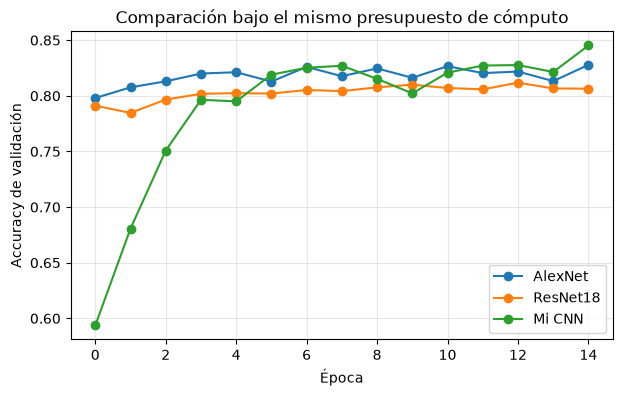

In [16]:
plt.figure(figsize=(7, 4))
for nombre, r in resultados.items():
    plt.plot(r["historial"]["val_acc"], marker="o", label=nombre)
plt.xlabel("Época")
plt.ylabel("Accuracy de validación")
plt.title("Comparación bajo el mismo presupuesto de cómputo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Para su reporte

- Copien la tabla y la gráfica de arriba.
- ¿Su CNN (desde cero) superó a los 3 baselines (feature extraction con ImageNet)? ¿A cuántos? Compárenlo también en la columna "Accuracy / 100K params entrenables" — esa es la métrica de EFICIENCIA, no solo de accuracy bruto.
- Muestren 5 ejemplos del conjunto de prueba mal clasificados por su mejor modelo (pueden adaptar el código de la celda de "un vistazo rápido a los datos" de la Sección 1).
- Expliquen qué decisiones de arquitectura creen que más ayudaron (o perjudicaron) — y si creen que vale la pena, en general, construir algo propio y compacto en vez de apoyarse en una red preentrenada.

Mi CNN: 1793 errores de 10000 en prueba

Confusiones más frecuentes (real -> predicha):
  dog        -> cat        109
  cat        -> dog        102
  bird       -> frog       102
  cat        -> frog       80
  dog        -> horse      73
  bird       -> deer       72

Accuracy por clase:
  airplane   0.810
  automobile 0.902
  bird       0.672
  cat        0.645
  deer       0.832
  dog        0.696
  frog       0.931
  horse      0.896
  ship       0.924
  truck      0.899


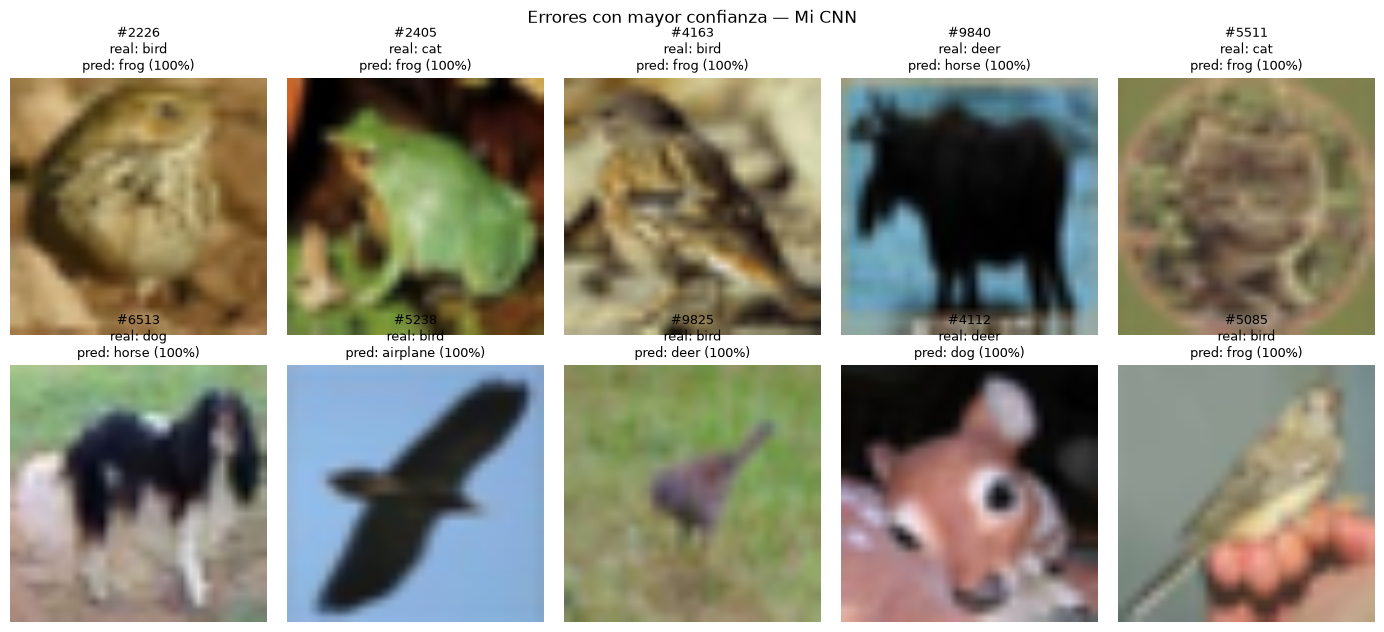


 Índice  Real       Predicha    Conf.  P(real)  Lugar de la real
   2226  bird       frog       100.0%     0.0%                 3
   2405  cat        frog       100.0%     0.0%                 3
   4163  bird       frog       100.0%     0.0%                 4
   9840  deer       horse      100.0%     0.0%                 2
   5511  cat        frog       100.0%     0.0%                 3
   6513  dog        horse      100.0%     0.0%                 2
   5238  bird       airplane   100.0%     0.0%                 2
   9825  bird       deer       100.0%     0.0%                 4
   4112  deer       dog        100.0%     0.0%                 4
   5085  bird       frog       100.0%     0.0%                 2


In [ ]:
# Análisis de errores: ejemplos mal clasificados del conjunto de prueba
NOMBRE_MODELO = "Mi CNN"   # cambien a "VGG16" para ver los errores del mejor baseline
N_MOSTRAR = 10

modelo_eval = resultados[NOMBRE_MODELO]["modelo"]
modelo_eval.eval()
clases = train_full.classes

todas_probs, todas_etiquetas = [], []
with torch.no_grad():
    for x, y in test_loader:
        todas_probs.append(torch.softmax(modelo_eval(x.to(device)), dim=1).cpu())
        todas_etiquetas.append(y)
probs = torch.cat(todas_probs)
etiquetas_test = torch.cat(todas_etiquetas)
confianza, preds = probs.max(dim=1)

errores = (preds != etiquetas_test).nonzero().flatten()
errores = errores[confianza[errores].argsort(descending=True)]   # primero los errores más "seguros"
print(f"{NOMBRE_MODELO}: {len(errores)} errores de {len(etiquetas_test)} en prueba")

# Matriz de confusión: confusiones más frecuentes y accuracy por clase
num_clases = len(clases)
matriz = torch.zeros(num_clases, num_clases, dtype=torch.int64)
for r, p in zip(etiquetas_test, preds):
    matriz[r, p] += 1
pares = sorted(((matriz[i, j].item(), clases[i], clases[j])
                for i in range(num_clases) for j in range(num_clases) if i != j), reverse=True)
print("\nConfusiones más frecuentes (real -> predicha):")
for n, r, p in pares[:6]:
    print(f"  {r:10s} -> {p:10s} {n}")
print("\nAccuracy por clase:")
for i, nombre_clase in enumerate(clases):
    print(f"  {nombre_clase:10s} {matriz[i, i].item() / matriz[i].sum().item():.3f}")

# Cuadrícula de errores (misma idea que "un vistazo rápido a los datos" de la Sección 1)
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(14, 6.4))
for ax, idx in zip(axes.flatten(), errores[:N_MOSTRAR].tolist()):
    img, real = test_set[idx]
    ax.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"#{idx}\nreal: {clases[real]}\npred: {clases[preds[idx]]} ({confianza[idx]:.0%})", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Errores con mayor confianza — {NOMBRE_MODELO}")
plt.tight_layout()
plt.show()

print(f"\n{'Índice':>7}  {'Real':10s} {'Predicha':10s} {'Conf.':>6}  {'P(real)':>7}  {'Lugar de la real':>16}")
for idx in errores[:N_MOSTRAR].tolist():
    r = etiquetas_test[idx].item()
    lugar = (probs[idx].argsort(descending=True) == r).nonzero().item() + 1
    print(f"{idx:>7}  {clases[r]:10s} {clases[preds[idx]]:10s} {confianza[idx]:>6.1%}  {probs[idx, r]:>7.1%}  {lugar:>16}")